# 09 — Historical factor testing and weight evaluation

**Research question:** Did companies with selected financial characteristics subsequently deliver stronger price returns or smaller losses, and how much confidence should that give us in each factor?

This experiment rebuilds selections using information available at each historical date. It compares six factor research baskets, review-frequency sensitivities and a three-year buy-and-hold test aligned with the assignment. Annual reselection is shown only as a historical reference. The final factor weights are weights in a research score, rather than allocations to individual stocks.

**Information cutoff:** 31 December 2025. Financial figures for 2025 are provisional estimates known on that date. Historical performance here is **price return excluding dividends**.

## ⭐ 1. Inputs, timing and what we can learn

The approved cleaned CSVs preserve the MGS, QCK and BSL corrections. Each financial record enters a signal only after its availability date; cleaning is not repeated.

Historical financial releases are dated 31 March. Signals use information known that day and trades occur at the next available closing price. Three-year growth first becomes available in March 2020. The common study therefore contains **five complete annual holding periods**, from April 2020 to April 2025. A March 2025 selection cannot provide a complete twelve-month result within the supplied history.

Five observations provide limited evidence. Results may reflect particular companies, sectors or years in this fictional universe, rather than a dependable future relationship.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image, Markdown

project_root = Path.cwd().resolve()
if project_root.name == "notebooks":
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.data_loader import load_cleaned_data
from src.research.backtesting import run_study, save_study

annual, prices = load_cleaned_data(project_root / "data" / "Cleaned")
print(f"Inputs: {annual['ticker'].nunique()} companies; prices through {prices['Date'].max().date()}.")

Inputs: 20 companies; prices through 2025-12-31.


## ⭐ 2. Factor definitions

Each valid metric receives equal weight within its factor after direction-aware percentile ranking among eligible companies. Every required metric must be valid. The ten highest factor scores form an initially equal-weight basket. Boundary ties are resolved alphabetically by ticker.

| Factor | Metrics | Window | Preferred direction |
|:--|:--|:--|:--|
| Growth | Revenue CAGR; EPS growth | Three-year revenue CAGR; latest annual EPS growth with positive comparable earnings | Higher |
| Profitability | Average profit margin; margin stability | Three annual margin observations | Higher average; lower standard deviation |
| Cash generation | Latest FCF margin; average FCF margin | Latest year and three-year average | Higher |
| Financial resilience | Net debt / positive FCF | Latest known annual information | Lower |
| Valuation | Earnings yield; FCF yield | Selection-date price and latest known annual figures | Higher; losses and cash consumption remain signed |
| Low price risk | Annualised volatility; maximum drawdown | Prior twelve months | Lower volatility; drawdown closer to zero |

CDB, BSL and CRM are excluded from cash-generation, financial-resilience and valuation baskets because the industrial FCF or leverage comparisons are not comparable. The valuation factor uses both earnings yield and FCF yield, so eligibility requires both. Nonpositive FCF makes net debt/FCF undefined. Their specialist credit and capital measures remain available in the earlier notebooks.

The names summarize the measurements. Fast growth alone does not establish business quality, and a high yield does not establish an attractive investment. Sector neutrality is not assumed.

## 3. Run the common-period study

Annual review is the main approach. March/September review is the alternative. Both use the same start and end dates. Stock weights drift with prices between reviews. Reported turnover excludes entry and final liquidation, while transaction-cost calculations include both. Turnover is half the value bought plus sold, divided by elapsed years.

Results are reported gross and with an illustrative **25 basis point cost on the value bought and sold**. Each factor is compared with the supplied benchmark and an equal-weight basket of its eligible companies. The latter comparison matters when missing or inapplicable fields shrink the opportunity set.

In [2]:
study = run_study(annual, prices)
summary = study["summary"].copy()
nav = study["nav"].copy()
selections = study["selections"].copy()

print(f"Common daily study span: {pd.to_datetime(nav['Date']).min().date()} to {pd.to_datetime(nav['Date']).max().date()}")
print("Factors:", ", ".join(sorted(summary["factor"].unique())))
print("Schedules:", ", ".join(sorted(summary["schedule"].unique())))
print("Trading-cost assumptions (basis points):", sorted(summary["cost_bps"].unique()))

Common daily study span: 2020-04-01 to 2025-04-01
Factors: Cash generation, Financial resilience, Growth, Low price risk, Profitability, Valuation
Schedules: Annual, Six-month
Trading-cost assumptions (basis points): [np.int64(0), np.int64(25)]


### Eligibility and selections

Missing values are not replaced with zero. If a factor has only a small eligible universe, a top-ten basket is less selective. Check the eligible-universe baseline and the exclusion reasons before interpreting performance.

In [3]:
eligibility = (selections.groupby(["schedule", "signal_date", "factor"], dropna=False)
    .agg(universe=("ticker", "nunique"), eligible=("eligible", "sum"), selected=("selected", "sum"))
    .reset_index())
display(eligibility)

exclusions = selections.loc[~selections["eligible"].astype(bool),
    ["schedule", "signal_date", "factor", "ticker", "reason"]]
print("Exclusion reasons: first occurrence per factor, ticker and reason")
display(exclusions.drop_duplicates(["factor", "ticker", "reason"]).reset_index(drop=True))

,schedule,signal_date,factor,universe,eligible,selected
0,Annual,2020-03-31,Cash generation,20,17,10
1,Annual,2020-03-31,Financial resilience,20,13,10
2,Annual,2020-03-31,Growth,20,16,10
3,Annual,2020-03-31,Low price risk,20,20,10
4,Annual,2020-03-31,Profitability,20,20,10
...,...,...,...,...,...,...
85,Six-month,2024-09-30,Financial resilience,20,13,10
86,Six-month,2024-09-30,Growth,20,17,10
87,Six-month,2024-09-30,Low price risk,20,20,10
88,Six-month,2024-09-30,Profitability,20,20,10


Exclusion reasons: first occurrence per factor, ticker and reason


,schedule,signal_date,factor,ticker,reason
0,Annual,2020-03-31,Growth,FAI,Undefined/missing: eps_growth
1,Annual,2020-03-31,Growth,QCK,Undefined/missing: eps_growth
2,Annual,2020-03-31,Growth,VGB,Undefined/missing: eps_growth
3,Annual,2020-03-31,Growth,VTF,Undefined/missing: eps_growth
4,Annual,2020-03-31,Cash generation,BSL,Specialist financial: industrial cash-flow/lev...
5,Annual,2020-03-31,Cash generation,CDB,Specialist financial: industrial cash-flow/lev...
6,Annual,2020-03-31,Cash generation,CRM,Specialist financial: industrial cash-flow/lev...
7,Annual,2020-03-31,Financial resilience,BSL,Specialist financial: industrial cash-flow/lev...
8,Annual,2020-03-31,Financial resilience,CDB,Specialist financial: industrial cash-flow/lev...
9,Annual,2020-03-31,Financial resilience,CRM,Specialist financial: industrial cash-flow/lev...


In [4]:
first_signal = selections["signal_date"].min()
first_schedule = sorted(selections["schedule"].unique())[0]
example = selections.loc[
    selections["signal_date"].eq(first_signal)
    & selections["schedule"].eq(first_schedule)
    & selections["selected"].astype(bool),
    ["factor", "ticker", "sector", "score", "signal_date", "execution_date"]
].sort_values(["factor", "score", "ticker"], ascending=[True, False, True])
print("First selections: compare signal date and execution date")
display(example.round({"score": 3}))

First selections: compare signal date and execution date


,factor,ticker,sector,score,signal_date,execution_date
215,Cash generation,ORP,Healthcare,1.000,2020-03-31,2020-04-01
213,Cash generation,MGS,Technology,0.941,2020-03-31,2020-04-01
207,Cash generation,FFF,Consumer,0.882,2020-03-31,2020-04-01
201,Cash generation,BFC,Technology,0.824,2020-03-31,2020-04-01
205,Cash generation,CSE,Industrials,0.765,2020-03-31,2020-04-01
211,Cash generation,HLM,Healthcare,0.706,2020-03-31,2020-04-01
214,Cash generation,NCL,Technology,0.647,2020-03-31,2020-04-01
210,Cash generation,HHM,Consumer,0.588,2020-03-31,2020-04-01
200,Cash generation,APR,Industrials,0.471,2020-03-31,2020-04-01
217,Cash generation,THL,Consumer,0.471,2020-03-31,2020-04-01


## 4. Growth and loss severity together

CAGR measures compounded growth using elapsed calendar time. Volatility is the standard deviation of daily returns scaled by the square root of 252 trading days. Sharpe uses the project's 3% annual risk-free assumption. Maximum drawdown is the most negative fall from a preceding basket high; closer to zero is less severe.

Read returns alongside loss severity, volatility, costs, turnover and benchmark-relative performance.

In [5]:
shown = summary.copy()
percentage_columns = ["cagr", "annualised_volatility", "max_drawdown", "benchmark_relative_return", "eligible_cagr"]
shown[percentage_columns] = shown[percentage_columns] * 100
shown = shown.rename(columns={
    "cagr": "CAGR (%)",
    "eligible_cagr": "Eligible-universe CAGR (%)",
    "annualised_volatility": "Volatility (% annual)",
    "max_drawdown": "Maximum drawdown (%)",
    "benchmark_relative_return": "Cumulative relative return vs benchmark (%)",
    "turnover_annualised": "Annualised turnover (x)",
})
display(shown.sort_values(["schedule", "cost_bps", "factor"]).round(3))

,factor,schedule,cost_bps,CAGR (%),Volatility (% annual),sharpe,Maximum drawdown (%),Annualised turnover (x),Cumulative relative return vs benchmark (%),Eligible-universe CAGR (%)
4,Cash generation,Annual,0,28.206,6.660,3.307,-7.919,0.090,55.488,19.928
6,Financial resilience,Annual,0,26.577,6.626,3.131,-7.919,0.075,45.856,23.634
0,Growth,Annual,0,23.260,7.082,2.560,-8.493,0.288,27.724,23.935
10,Low price risk,Annual,0,29.304,6.639,3.445,-7.457,0.140,62.256,20.848
2,Profitability,Annual,0,30.731,6.841,3.505,-6.172,0.179,71.409,20.848
8,Valuation,Annual,0,25.993,6.903,2.941,-7.106,0.084,42.522,19.928
5,Cash generation,Annual,25,28.021,6.660,3.285,-7.919,0.090,54.366,19.928
7,Financial resilience,Annual,25,26.403,6.626,3.110,-7.919,0.075,44.856,23.634
1,Growth,Annual,25,22.960,7.083,2.525,-8.493,0.288,26.175,23.935
11,Low price risk,Annual,25,29.084,6.640,3.419,-7.457,0.140,60.881,20.848


### Complete review-period returns

These are holding-period returns, not calendar-year returns. Annual review periods are approximately twelve months; six-month review periods are approximately six months. Use the common-period summary to compare the schedules, rather than averaging unequal-length holding-period returns.

In [6]:
periods = study["period_returns"].copy()
periods["Holding-period return (%)"] = periods["return"] * 100
display(periods.drop(columns="return").sort_values(
    ["schedule", "cost_bps", "start_date", "factor"]).round(3))

/var/folders/9b/zgn73v8j45s_hg_rw09skl7m0000gn/T/ipykernel_44434/3156863779.py:4: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ["schedule", "cost_bps", "start_date", "factor"]).round(3))


,start_date,end_date,factor,schedule,cost_bps,Holding-period return (%)
20,2020-04-01,2021-04-01,Cash generation,Annual,0,49.808
30,2020-04-01,2021-04-01,Financial resilience,Annual,0,41.160
0,2020-04-01,2021-04-01,Growth,Annual,0,32.451
50,2020-04-01,2021-04-01,Low price risk,Annual,0,48.608
10,2020-04-01,2021-04-01,Profitability,Annual,0,61.353
...,...,...,...,...,...,...
139,2024-10-01,2025-04-01,Financial resilience,Six-month,25,14.894
79,2024-10-01,2025-04-01,Growth,Six-month,25,14.540
179,2024-10-01,2025-04-01,Low price risk,Six-month,25,13.686
99,2024-10-01,2025-04-01,Profitability,Six-month,25,17.937


## 5. Six-month forward results

A basket selected annually can still have its return measured six months later. This observation does not imply that the holdings were replaced then. The forward-return table reports six- and twelve-month results. An incomplete endpoint lies outside the supplied data and is not a complete holding period.

In [7]:
forward = study["forward_returns"].copy()
forward["Forward price return (%)"] = forward["return"] * 100
display(forward.drop(columns="return").sort_values(
    ["signal_date", "factor", "horizon_months"]).round(3))

/var/folders/9b/zgn73v8j45s_hg_rw09skl7m0000gn/T/ipykernel_44434/4233049501.py:4: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ["signal_date", "factor", "horizon_months"]).round(3))


,signal_date,execution_date,factor,horizon_months,exit_date,complete,Forward price return (%)
4,2020-03-31,2020-04-01,Cash generation,6,2020-10-01,True,28.075
5,2020-03-31,2020-04-01,Cash generation,12,2021-04-01,True,49.808
6,2020-03-31,2020-04-01,Financial resilience,6,2020-10-01,True,24.017
7,2020-03-31,2020-04-01,Financial resilience,12,2021-04-01,True,41.160
0,2020-03-31,2020-04-01,Growth,6,2020-10-01,True,19.608
...,...,...,...,...,...,...,...
71,2025-03-31,2025-04-01,Low price risk,12,NaT,False,NaN
62,2025-03-31,2025-04-01,Profitability,6,2025-10-01,True,11.891
63,2025-03-31,2025-04-01,Profitability,12,NaT,False,NaN
68,2025-03-31,2025-04-01,Valuation,6,2025-10-01,True,11.570


## 6. Plots and exported results

The figures show cumulative growth, drawdowns, period returns, return versus risk, factor correlations, selection overlap, and review-schedule sensitivity. Tables and images are also saved under results so the evidence can be inspected outside Jupyter.

Matplotlib is building the font cache; this may take a moment.


### Cumulative price growth

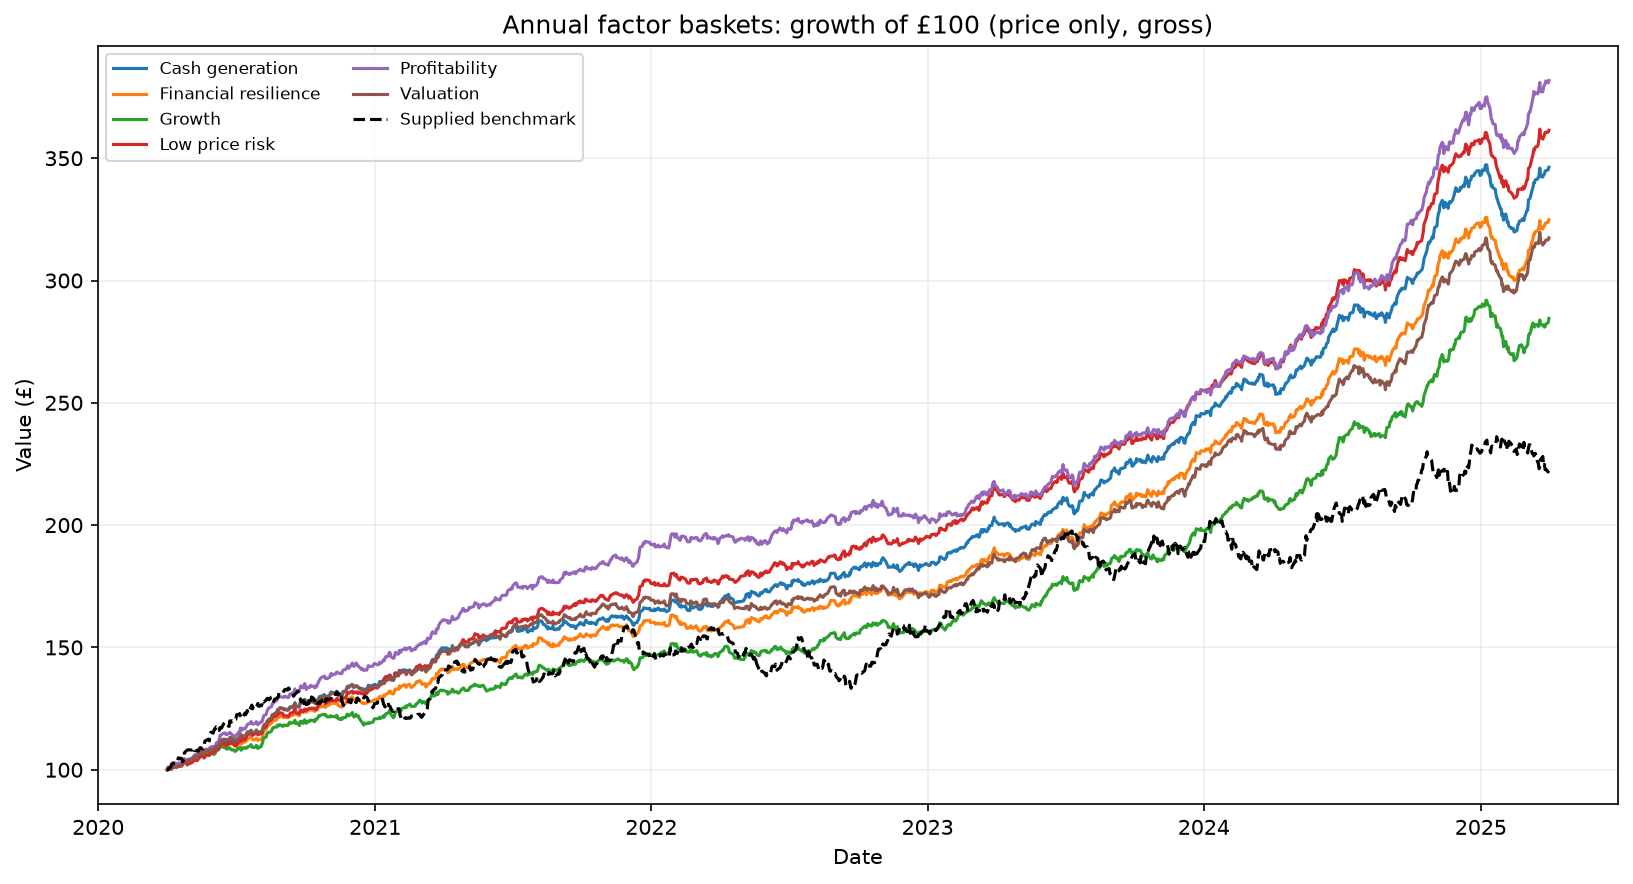

### Drawdown paths

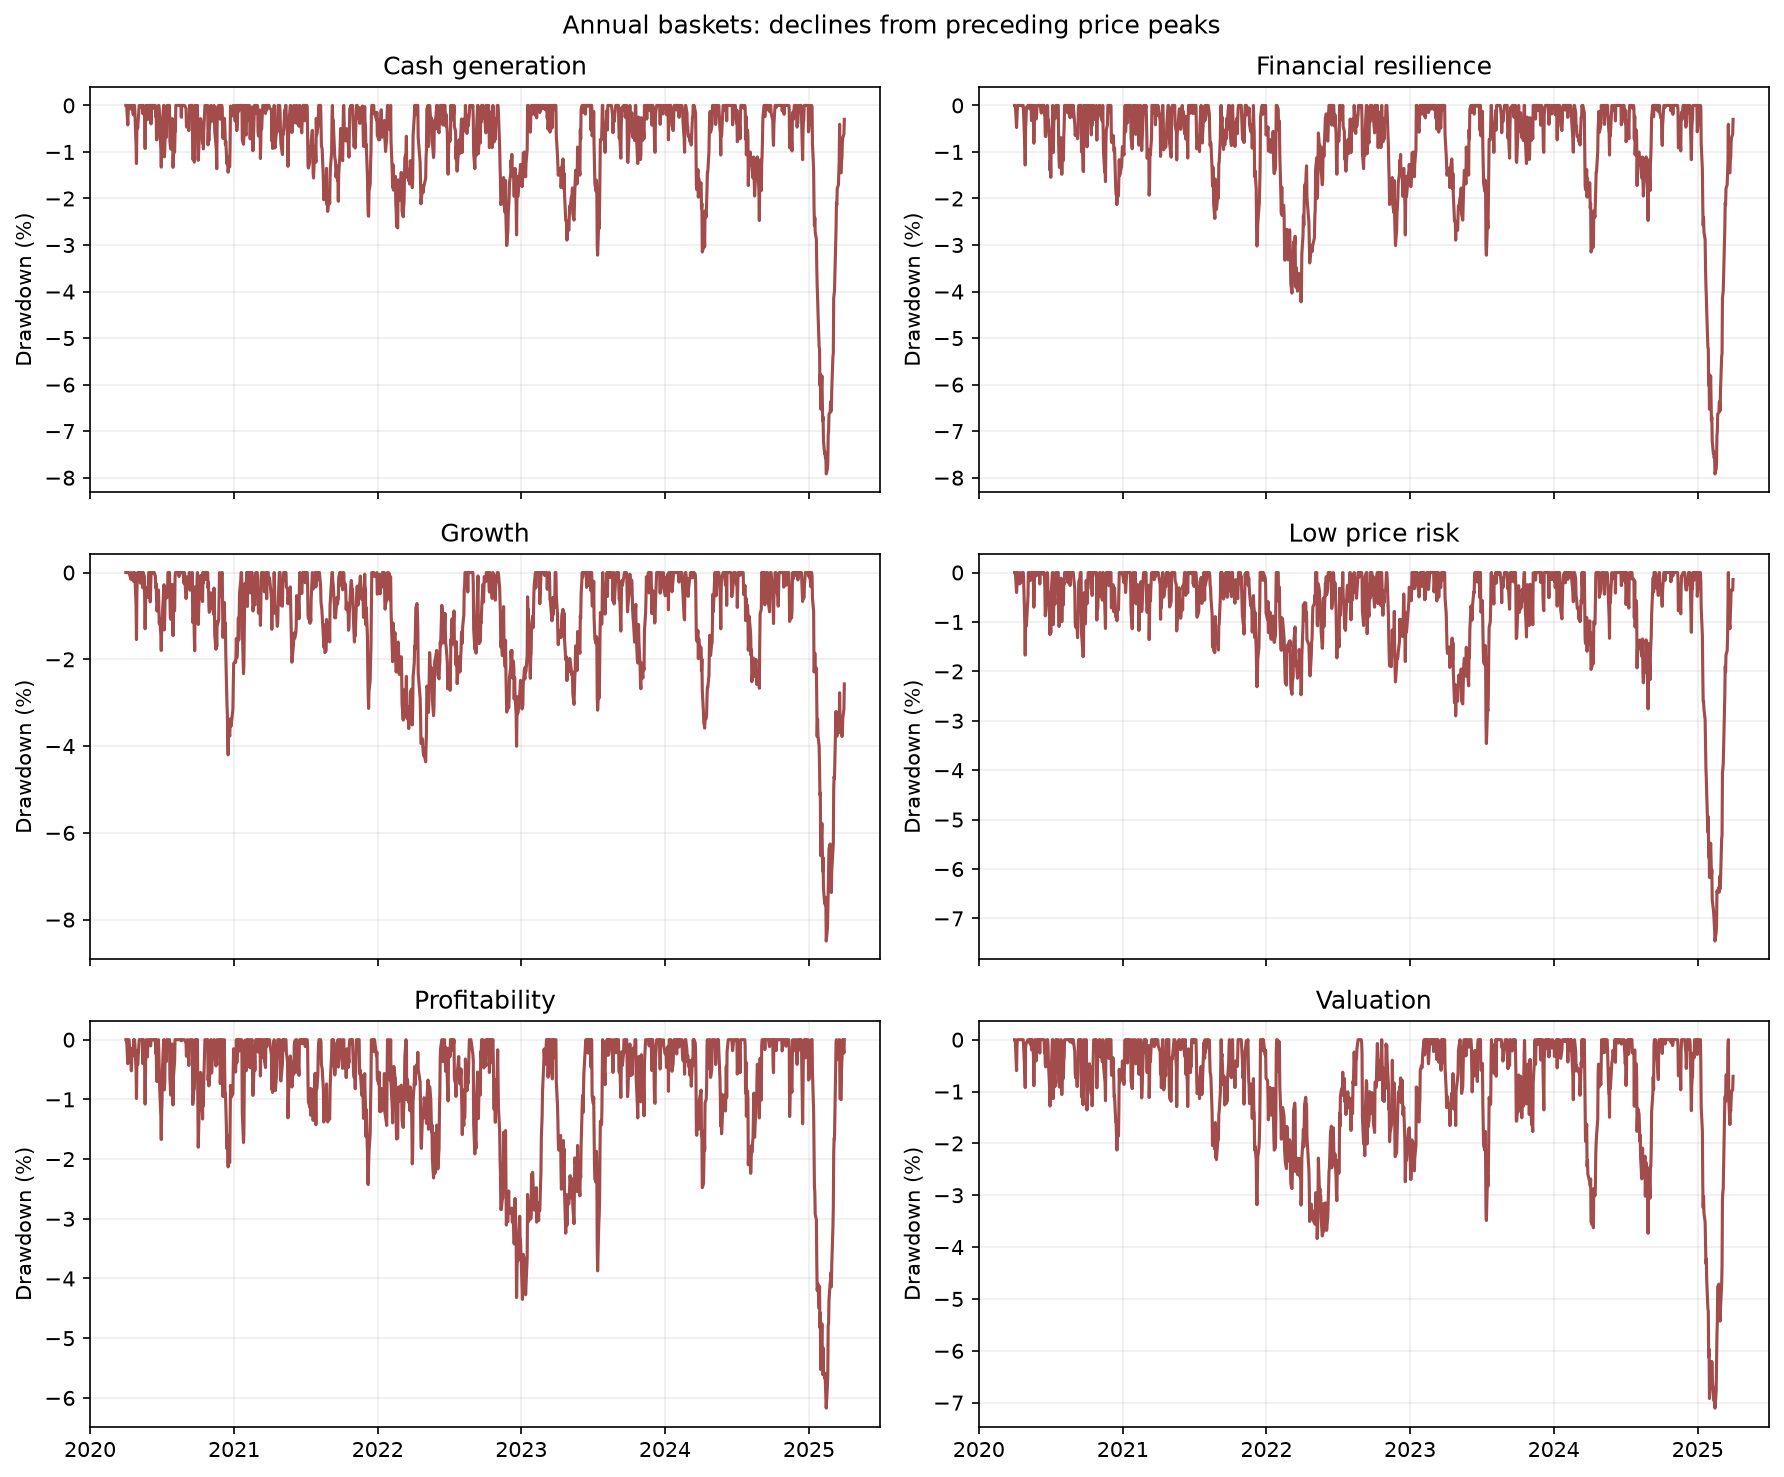

### Returns by annual holding period

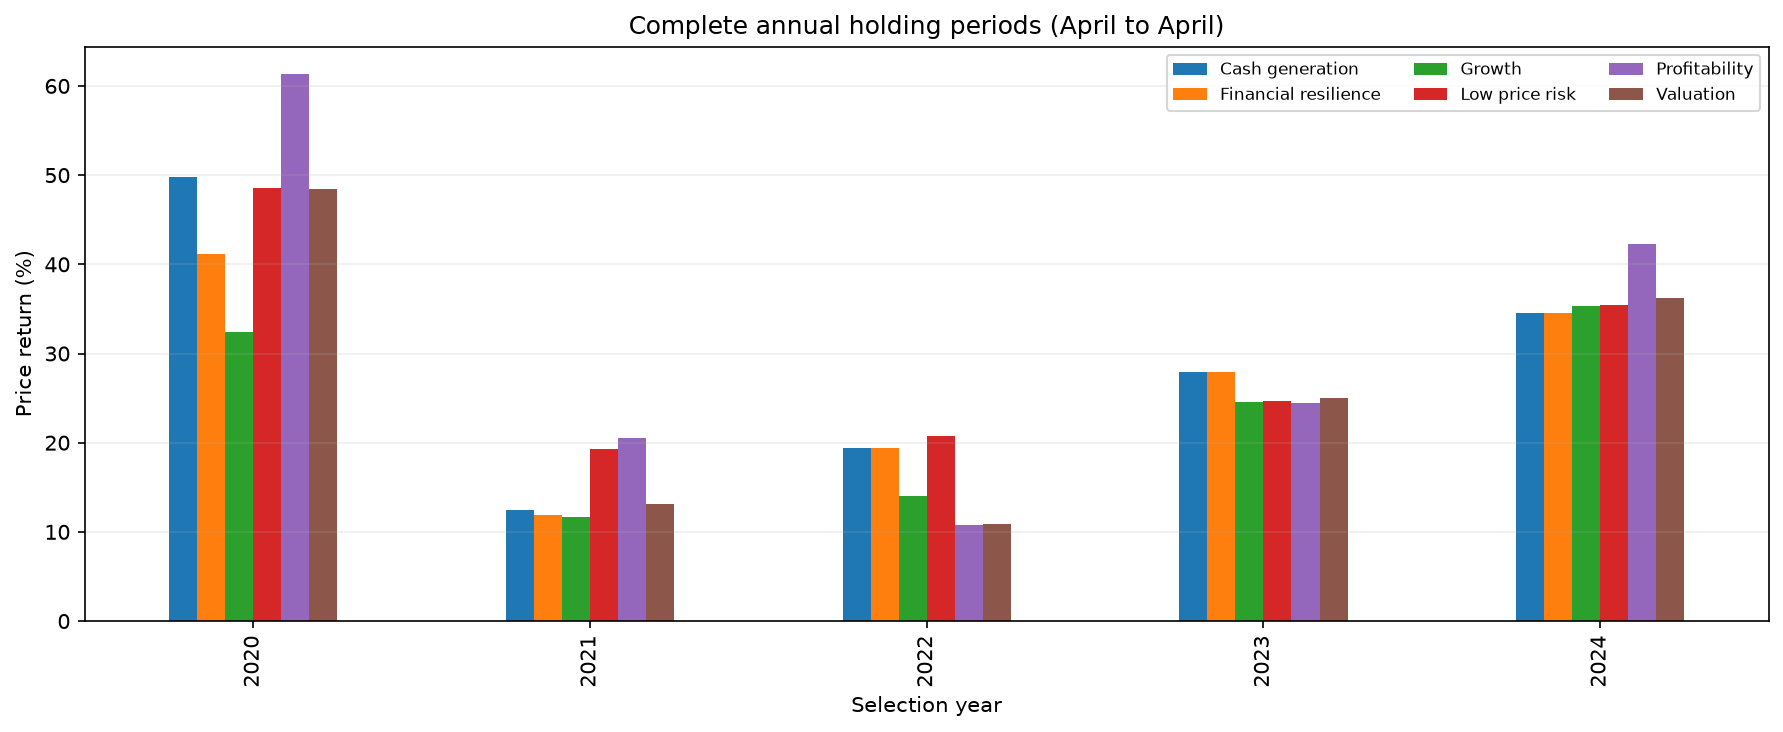

### Return versus volatility

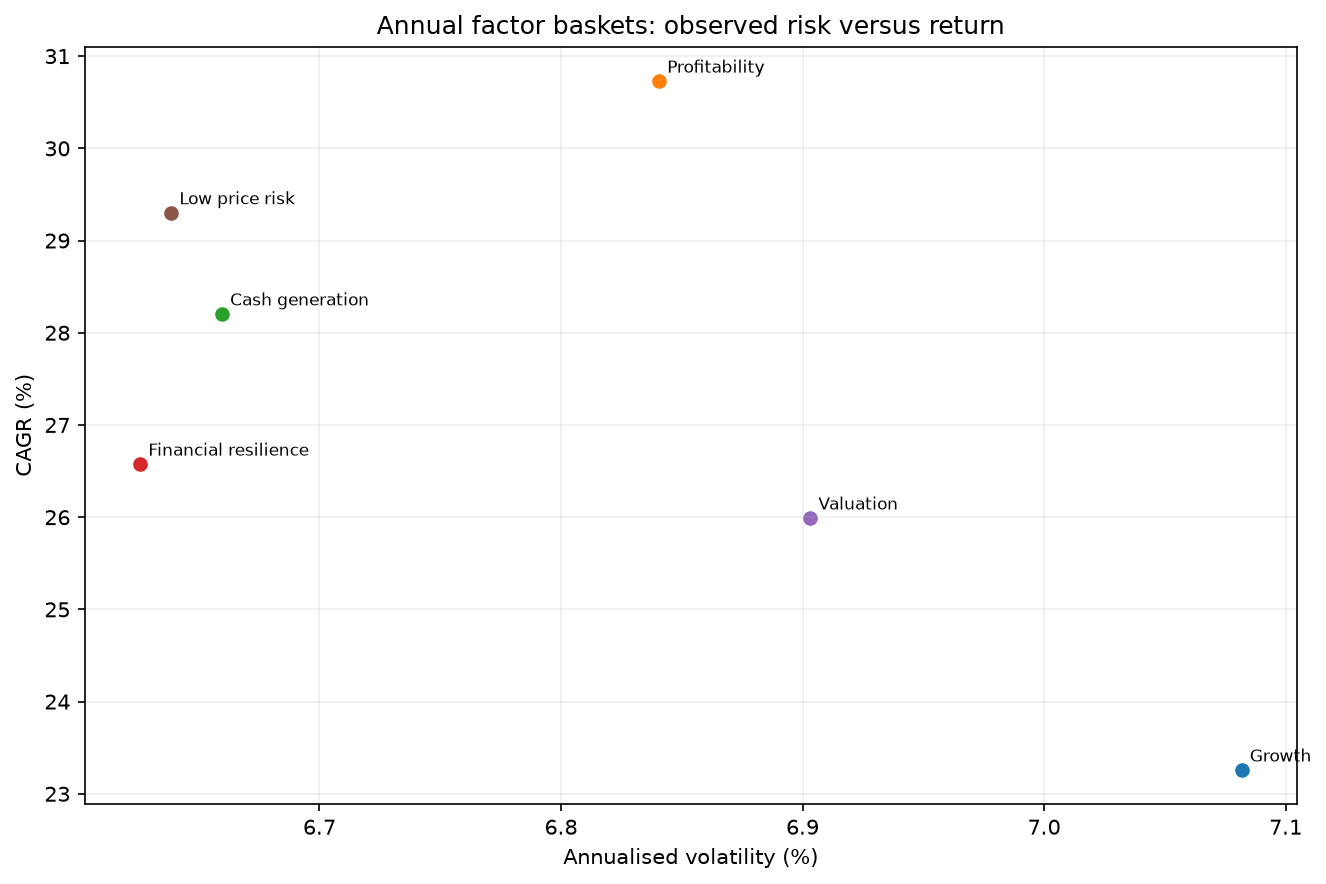

### Daily factor-return correlations

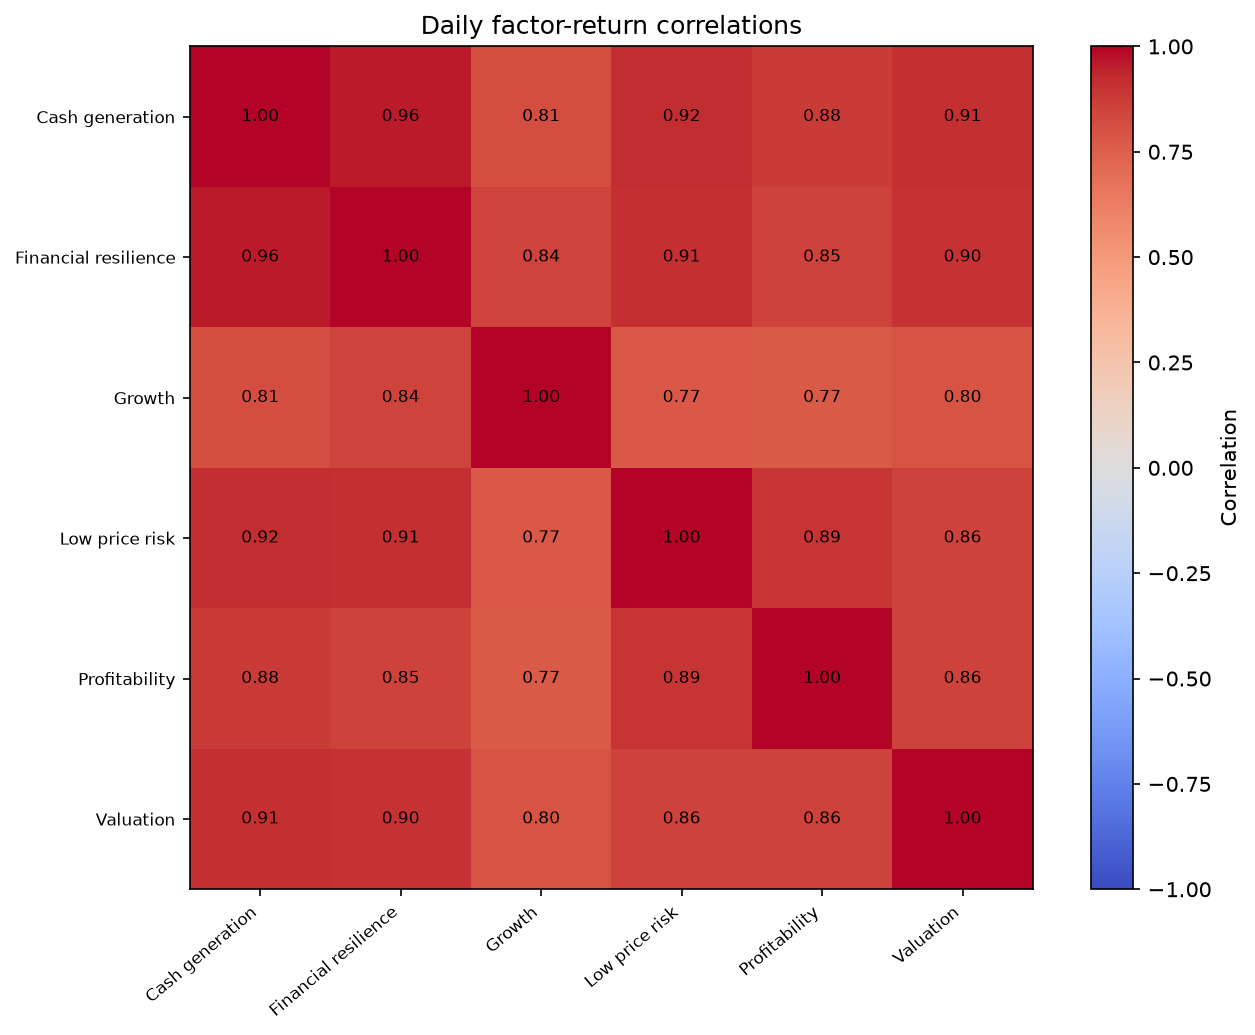

### Average top-ten selection overlap

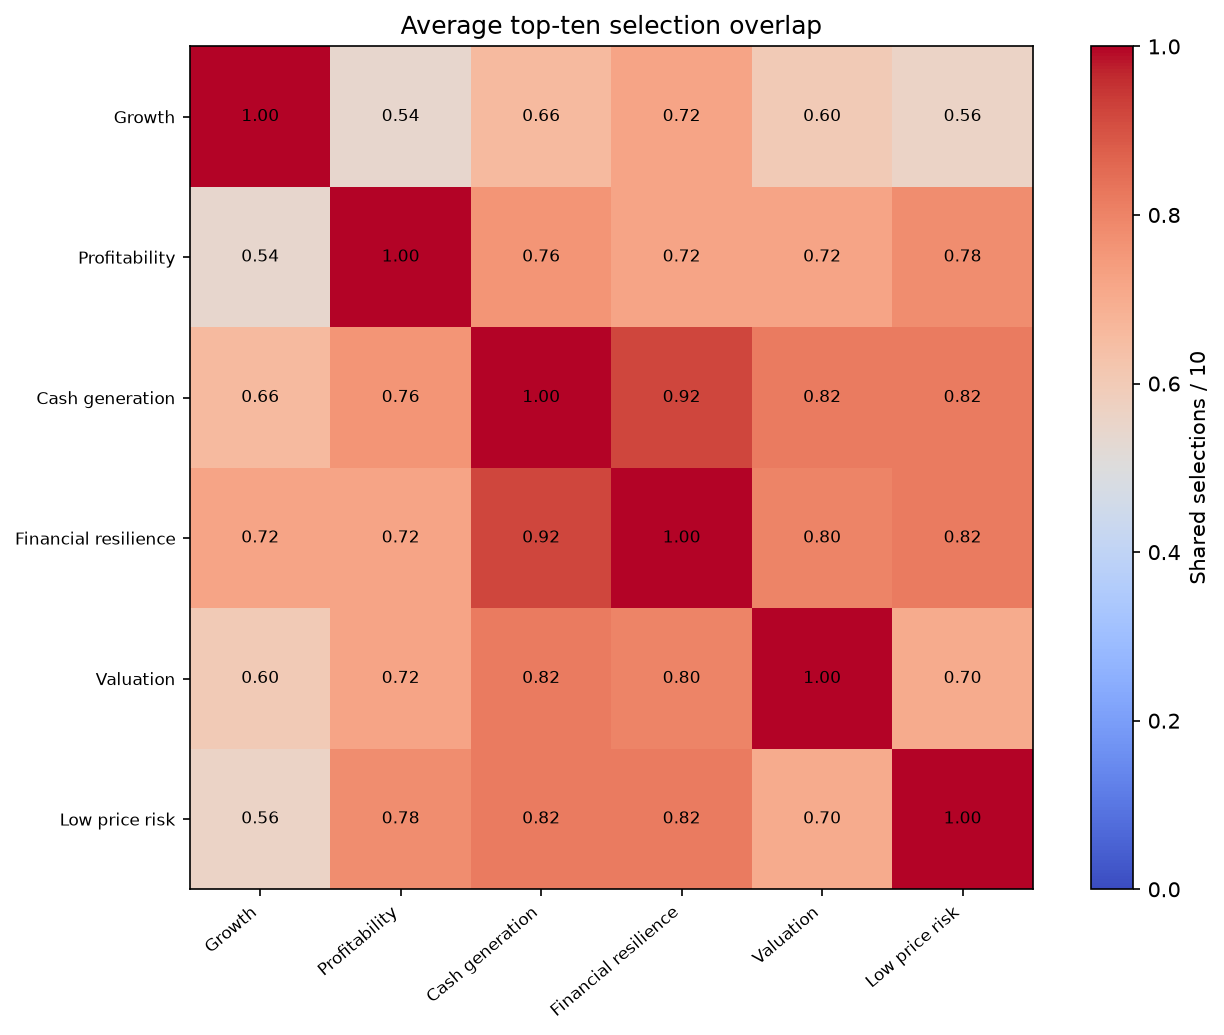

### Annual versus six-month reviews

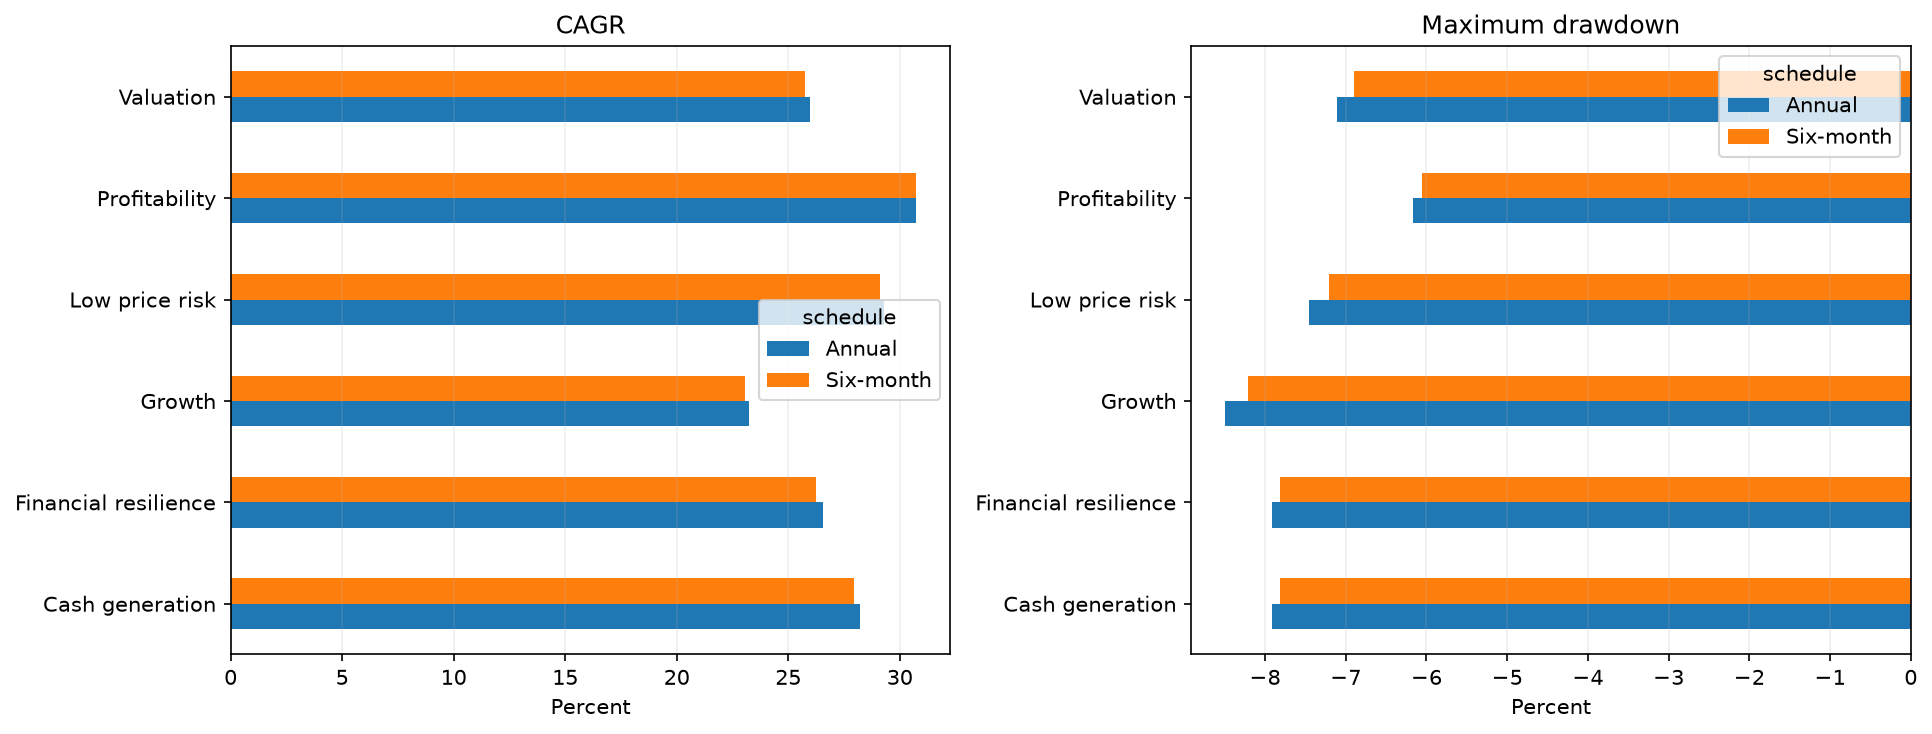

### Factor-weight sensitivity

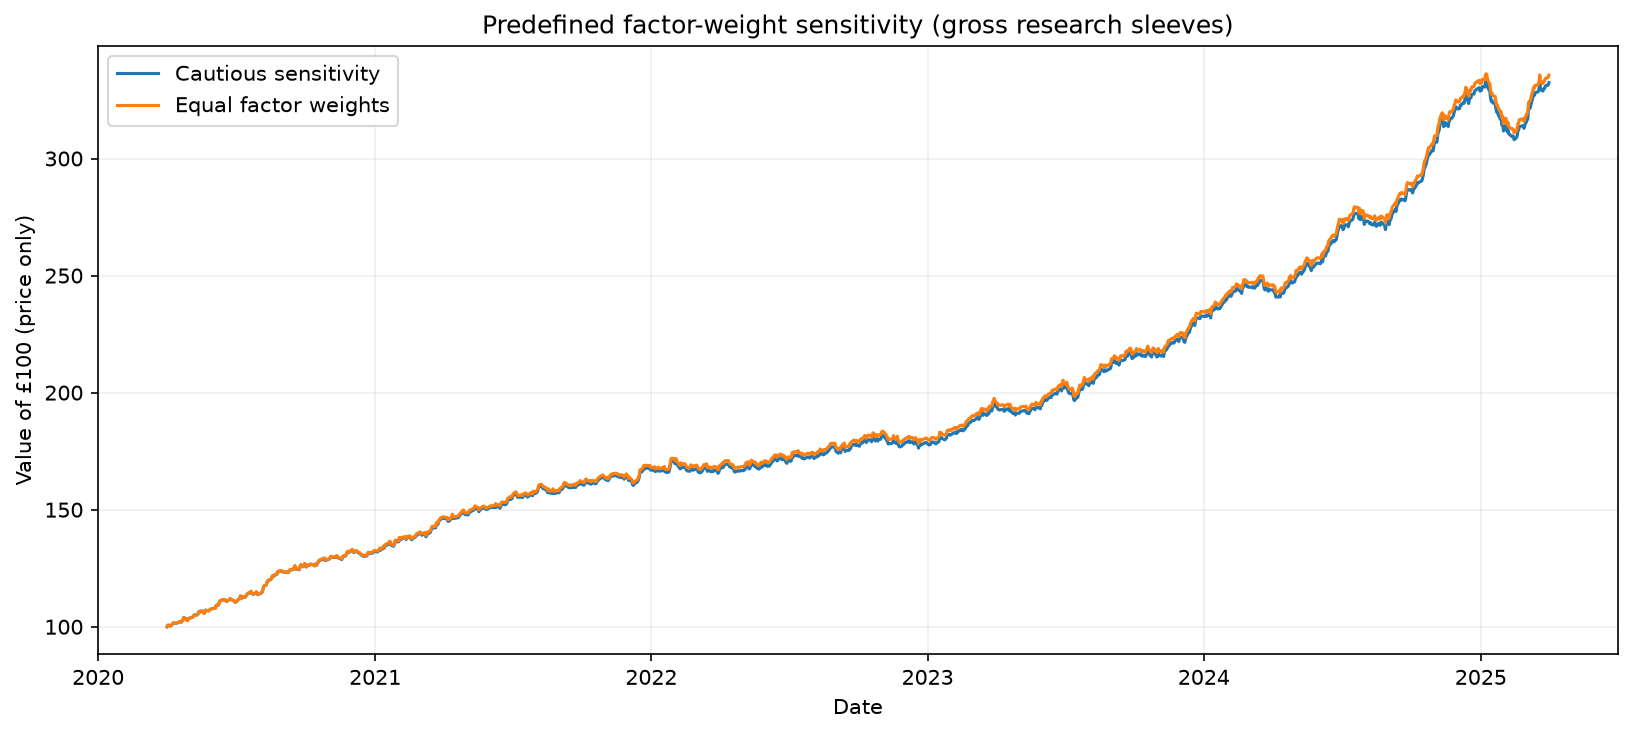

In [8]:
artifacts = save_study(study, project_root / "results")
for title, image_path in artifacts["plots"].items():
    display(Markdown(f"### {title}"))
    display(Image(filename=str(image_path)))

### Equal weights versus a cautious sensitivity

These gross research blends combine each factor's annual top-ten basket. They show the sensitivity of returns to weighting six factor sleeves; they do not show which weights are best. The same companies can occur in several sleeves, so changing sleeve weights can increase exposure to stocks already represented elsewhere. Overlap does not make a tilt pointless: it means the apparent benefit may come from repeatedly holding the same names, rather than from an independent factor effect. A combined company score must be backtested separately.

In [9]:
blend_comparison = study["blend_summary"].copy()
blend_weights = {
    "Equal factor weights": {factor: 1 / 6 for factor in study["weights"]["factor"]},
    "Cautious sensitivity": {
        "Growth": .15, "Profitability": .15, "Cash generation": .15,
        "Financial resilience": .25, "Valuation": .20, "Low price risk": .10,
    },
}
blend_comparison["Factor weights"] = blend_comparison["blend"].map(
    lambda name: "; ".join(f"{factor} {weight:.1%}" for factor, weight in blend_weights[name].items())
)
blend_percentage_columns = ["cagr", "annualised_volatility", "max_drawdown", "benchmark_relative_return"]
blend_comparison[blend_percentage_columns] = blend_comparison[blend_percentage_columns].mul(100)
blend_comparison = blend_comparison.rename(columns={
    "cagr": "CAGR (%)",
    "annualised_volatility": "Volatility (% annual)",
    "max_drawdown": "Maximum drawdown (%)",
    "benchmark_relative_return": "Cumulative relative return vs benchmark (%)",
})
display(blend_comparison.round(3))


,blend,CAGR (%),Volatility (% annual),sharpe,Maximum drawdown (%),turnover_annualised,Cumulative relative return vs benchmark (%),Factor weights
0,Equal factor weights,27.404,6.387,3.347,-7.504,NaN,50.681,Growth 16.7%; Profitability 16.7%; Cash genera...
1,Cautious sensitivity,27.159,6.404,3.309,-7.527,NaN,49.240,Growth 15.0%; Profitability 15.0%; Cash genera...


## 7. Overlap and sector concentration

Different factors can repeatedly select the same stocks. Their returns may consequently move together. The overlap matrix and sector composition show whether factor names translate into different selections.

In [10]:
print("Selection overlap matrix; see the plot for its labelled scale")
display(study["overlap"].round(3))

selected = selections.loc[selections["selected"].astype(bool)].copy()
sector_mix = (selected.groupby(["schedule", "signal_date", "factor", "sector"])
    .size().rename("companies").reset_index())
sector_mix["Initial basket weight (%)"] = sector_mix["companies"].div(
    sector_mix.groupby(["schedule", "signal_date", "factor"])["companies"].transform("sum")).mul(100)
display(sector_mix.round(2))

Selection overlap matrix; see the plot for its labelled scale


,Growth,Profitability,Cash generation,Financial resilience,Valuation,Low price risk
Growth,1.00,0.54,0.66,0.72,0.60,0.56
Profitability,0.54,1.00,0.76,0.72,0.72,0.78
Cash generation,0.66,0.76,1.00,0.92,0.82,0.82
Financial resilience,0.72,0.72,0.92,1.00,0.80,0.82
Valuation,0.60,0.72,0.82,0.80,1.00,0.70
Low price risk,0.56,0.78,0.82,0.82,0.70,1.00


/var/folders/9b/zgn73v8j45s_hg_rw09skl7m0000gn/T/ipykernel_44434/418118657.py:9: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(sector_mix.round(2))


,schedule,signal_date,factor,sector,companies,Initial basket weight (%)
0,Annual,2020-03-31,Cash generation,Consumer,3,30.0
1,Annual,2020-03-31,Cash generation,Healthcare,2,20.0
2,Annual,2020-03-31,Cash generation,Industrials,2,20.0
3,Annual,2020-03-31,Cash generation,Technology,3,30.0
4,Annual,2020-03-31,Financial resilience,Consumer,1,10.0
...,...,...,...,...,...,...
421,Six-month,2024-09-30,Profitability,Technology,3,30.0
422,Six-month,2024-09-30,Valuation,Consumer,3,30.0
423,Six-month,2024-09-30,Valuation,Healthcare,2,20.0
424,Six-month,2024-09-30,Valuation,Industrials,3,30.0


## ⭐ 8. Factor weights, missing data and limits

The starting research-score weights are **one-sixth per factor**, with equal metric weights inside each factor. A five-period backtest is too short to choose precise performance-fitted tilts. The tables below put factor performance, eligibility, overlap and both proposed weight sets side by side.

Missing data does **not** automatically mean a company is weak. In this dataset, lender and insurer cash-flow fields are structurally inapplicable or absent, so the industrial FCF and net-debt ratios exclude CDB, BSL and CRM. That is a comparability limit, not evidence of poor performance. It also means those three cannot receive a fair all-six-factor score under the current definitions. Keep a separate financial-sector assessment, or build sector-specific resilience factors from overdue loans and capital cushion for CDB/BSL and claims ratio and capital cover for CRM. Do not impute zero or silently redistribute their missing factor weights.

The overlap table reports shared top-ten holdings. If two baskets repeatedly hold the same companies, weighting both factors heavily can emphasize those companies twice. A combined-score selection test would reveal how that affects the final ranking; this notebook tests factor baskets separately.

In [11]:
weights = study["weights"].copy()
weights["Factor-score weight (%)"] = weights["weight"] * 100
display(weights.drop(columns="weight").round(4))
print(f"Underlying weights total: {weights['weight'].sum():.6%}")

for schedule, group in summary.loc[summary["cost_bps"].eq(0)].groupby("schedule"):
    highest_return = group.loc[group["cagr"].idxmax()]
    smallest_loss = group.loc[group["max_drawdown"].idxmax()]
    print(f"{schedule}: highest sample CAGR was {highest_return['factor']} ({highest_return['cagr']:.1%}); "
          f"smallest sample maximum drawdown was {smallest_loss['factor']} ({smallest_loss['max_drawdown']:.1%}).")

,factor,Factor-score weight (%)
0,Growth,16.6667
1,Profitability,16.6667
2,Cash generation,16.6667
3,Financial resilience,16.6667
4,Valuation,16.6667
5,Low price risk,16.6667


Underlying weights total: 100.000000%
Annual: highest sample CAGR was Profitability (30.7%); smallest sample maximum drawdown was Profitability (-6.2%).
Six-month: highest sample CAGR was Profitability (30.7%); smallest sample maximum drawdown was Profitability (-6.1%).


### ⭐ Factor results, eligibility and overlap in one table

Returns are annual-review gross results. Eligible counts vary by signal date and factor; all baskets still select ten. `Average overlap` is the mean number of shared stocks between this factor's top ten and each other factor's top ten, averaged across the five annual selections.


In [12]:
annual_gross = summary.query("schedule == 'Annual' and cost_bps == 0").set_index("factor")
semiannual_gross = summary.query("schedule == 'Six-month' and cost_bps == 0").set_index("factor")
annual_eligible = (selections.query("schedule == 'Annual'")
    .groupby(["factor", "signal_date"]).eligible.sum()
    .groupby("factor").agg(minimum="min", maximum="max"))
annual_selected = selections.query("schedule == 'Annual' and selected")
mean_sector_mix = (annual_selected.groupby(["factor", "sector"]).size()
    .div(50).rename("mean_initial_weight").reset_index())
mean_sector_text = mean_sector_mix.groupby("factor").apply(
    lambda rows: ", ".join(f"{row.sector} {row.mean_initial_weight:.0%}" for row in rows.itertuples()),
    include_groups=False,
)
overlap_values = []
for factor in study["overlap"].index:
    other_factors = study["overlap"].loc[factor].drop(factor)
    nearest = other_factors.idxmax()
    overlap_values.append({
        "factor": factor,
        "mean_shared_with_other_baskets (of 10)": other_factors.mean() * 10,
        "most_overlap_with": nearest,
        "shared_with_that_basket (of 10)": other_factors.max() * 10,
    })
overlap_table = pd.DataFrame(overlap_values).set_index("factor")
cautious_weights = {
    "Growth": .15, "Profitability": .15, "Cash generation": .15,
    "Financial resilience": .25, "Valuation": .20, "Low price risk": .10,
}
equal_weights = study["weights"].set_index("factor").weight
factor_table = pd.DataFrame(index=study["weights"].factor)
factor_table.index.name = "factor"
factor_table["equal research-score weight (%)"] = equal_weights * 100
factor_table["cautious sensitivity weight (%)"] = pd.Series(cautious_weights) * 100
factor_table["annual gross CAGR (%)"] = annual_gross.cagr * 100
factor_table["annual net CAGR at 25bp (%)"] = summary.query(
    "schedule == 'Annual' and cost_bps == 25").set_index("factor").cagr * 100
factor_table["annual max drawdown (%)"] = annual_gross.max_drawdown * 100
factor_table["semiannual gross CAGR (%)"] = semiannual_gross.cagr * 100
factor_table["eligible companies, min–max"] = annual_eligible.apply(
    lambda row: f"{int(row.minimum)}–{int(row.maximum)}", axis=1)
factor_table["average shared holdings with other baskets (of 10)"] = overlap_table[
    "mean_shared_with_other_baskets (of 10)"]
factor_table["most overlapping basket"] = overlap_table.most_overlap_with
factor_table["shared holdings with that basket (of 10)"] = overlap_table[
    "shared_with_that_basket (of 10)"]
factor_table["mean initial sector mix"] = mean_sector_text
print("One row per factor: returns, eligibility, overlap, weights, and sector mix")
display(factor_table.round({
    "equal research-score weight (%)": 2,
    "cautious sensitivity weight (%)": 2,
    "annual gross CAGR (%)": 2,
    "annual net CAGR at 25bp (%)": 2,
    "annual max drawdown (%)": 2,
    "semiannual gross CAGR (%)": 2,
    "average shared holdings with other baskets (of 10)": 1,
    "shared holdings with that basket (of 10)": 1,
}))

specialist_exclusions = (selections.query("schedule == 'Annual' and not eligible")
    .loc[lambda rows: rows.ticker.isin(["CDB", "BSL", "CRM"]),
         ["factor", "ticker", "reason"]]
    .drop_duplicates().sort_values(["factor", "ticker"]))
print("Specialist financial companies excluded from factors that use industrial FCF/leverage")
display(specialist_exclusions.set_index(["factor", "ticker"]))


One row per factor: returns, eligibility, overlap, weights, and sector mix


,equal research-score weight (%),cautious sensitivity weight (%),annual gross CAGR (%),annual net CAGR at 25bp (%),annual max drawdown (%),semiannual gross CAGR (%),"eligible companies, min–max",average shared holdings with other baskets (of 10),most overlapping basket,shared holdings with that basket (of 10),mean initial sector mix
factor,,,,,,,,,,,
Growth,16.67,15.0,23.26,22.96,-8.49,23.08,16–17,6.2,Financial resilience,7.2,"Consumer 8%, Financials 22%, Healthcare 20%, I..."
Profitability,16.67,15.0,30.73,30.48,-6.17,30.70,20–20,7.0,Low price risk,7.8,"Consumer 16%, Financials 22%, Healthcare 22%, ..."
Cash generation,16.67,15.0,28.21,28.02,-7.92,27.94,17–17,8.0,Financial resilience,9.2,"Consumer 24%, Financials 8%, Healthcare 20%, I..."
Financial resilience,16.67,25.0,26.58,26.40,-7.92,26.26,12–13,8.0,Cash generation,9.2,"Consumer 16%, Financials 10%, Healthcare 20%, ..."
Valuation,16.67,20.0,25.99,25.81,-7.11,25.75,17–17,7.3,Cash generation,8.2,"Consumer 30%, Healthcare 20%, Industrials 30%,..."
Low price risk,16.67,10.0,29.30,29.08,-7.46,29.09,20–20,7.4,Cash generation,8.2,"Consumer 20%, Financials 22%, Healthcare 14%, ..."


Specialist financial companies excluded from factors that use industrial FCF/leverage


reason
factor               ticker                                                   
Cash generation      BSL     Specialist financial: industrial cash-flow/lev...
                     CDB     Specialist financial: industrial cash-flow/lev...
                     CRM     Specialist financial: industrial cash-flow/lev...
Financial resilience BSL     Specialist financial: industrial cash-flow/lev...
                     CDB     Specialist financial: industrial cash-flow/lev...
                     CRM     Specialist financial: industrial cash-flow/lev...
Valuation            BSL     Specialist financial: industrial cash-flow/lev...
                     CDB     Specialist financial: industrial cash-flow/lev...
                     CRM     Specialist financial: industrial cash-flow/lev...

## ⭐ 9. Backtest the combined equal-factor company score

Each valid factor score is a percentile from 0 to 1. The combined score is the mean of the six factor scores, so each factor contributes one-sixth. We require a valid score for all six factors; no missing value is filled or redistributed. Compare annual baskets holding 5, 8 or 10 companies, with equal pound weights inside each basket. The 25bp sensitivity charges each buy and sell. This is the combined-score test missing from the preceding factor-basket comparison, and is still historical evidence rather than a recommendation.

The relevant score as at 31 December 2025 uses provisional 2025 figures available on that date. **CDB, BSL and CRM are excluded** because the current resilience factor uses industrial net debt/FCF. Other firms can also be excluded if their EPS growth or ratios are undefined. The final risk section records these exclusions as a limitation.

Combined-score backtest: annual review, equal pound weights, 2020–2025 common period


,factor,holding_count,schedule,cost_bps,CAGR (%),Volatility (% annual),sharpe,Maximum drawdown (%),turnover_annualised,Cumulative relative return vs benchmark (%),Eligible-universe CAGR (%)
0,Equal-factor composite,5,Annual,0,35.300,7.757,3.541,-5.115,0.124,103.522,23.634
1,Equal-factor composite,5,Annual,25,35.081,7.756,3.521,-5.115,0.124,101.881,23.634
2,Equal-factor composite,8,Annual,0,31.435,7.009,3.499,-7.513,0.141,76.070,23.634
3,Equal-factor composite,8,Annual,25,31.211,7.011,3.474,-7.513,0.141,74.577,23.634
4,Equal-factor composite,10,Annual,0,28.955,6.668,3.390,-7.476,0.072,60.081,23.634
5,Equal-factor composite,10,Annual,25,28.780,6.668,3.370,-7.476,0.072,58.995,23.634


Companies with all six scores at each annual signal


,signal_date,companies,eligible
0,2020-03-31,20,13
1,2021-03-31,20,12
2,2022-03-31,20,13
3,2023-03-31,20,13
4,2024-03-31,20,13


Companies excluded from the combined score; exclusions are missing data, not poor performance


,ticker,sector,reason
2,QCK,Consumer,At least one factor score undefined
16,BSL,Financials,At least one factor score undefined
15,CDB,Financials,Eligible on all six factors
14,CRM,Financials,Eligible on all six factors
30,GVH,Healthcare,Eligible on all six factors
8,VGB,Healthcare,Eligible on all six factors
28,VGB,Healthcare,At least one factor score undefined
0,VTF,Industrials,Eligible on all six factors
12,FAI,Technology,Eligible on all six factors


Eligible combined scores at the investment information date (screen, not recommendations)


,ticker,company,sector,score
5,MGS,Marigold Systems,Technology,0.773
18,BFC,Bluefin Cyber,Technology,0.767
3,ORP,Oriel Pharma,Healthcare,0.742
13,CSE,ClearSpan Engineering,Industrials,0.682
6,LNP,Lantern Payments,Financials,0.649
11,FFF,Field & Fable Foods,Consumer,0.647
4,NCL,Northstar Cloud,Technology,0.623
19,APR,Apex Rail,Industrials,0.591
7,HLM,Helix Medical,Healthcare,0.548
9,HHM,Hearth & Home,Consumer,0.528


Illustrative equal-pound sizing before whole-share rounding or transaction costs


,number_of_holdings,equal_budget_per_holding_gbp,initial_weight_per_holding_pct
0,5,20000.0,20.0
1,8,12500.0,12.5
2,10,10000.0,10.0


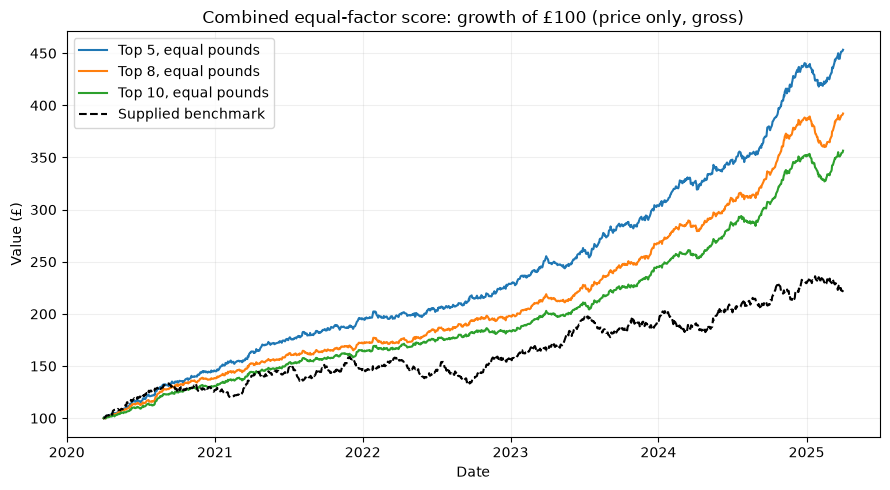

Saved combined-score tables and plot under results/.


In [13]:
import matplotlib.pyplot as plt
from src.research.backtesting import composite_snapshot, run_composite_study

composite_study = run_composite_study(annual, prices, holding_counts=(5, 8, 10))
combined_summary = composite_study["summary"].copy()
combined_percentages = ["cagr", "annualised_volatility", "max_drawdown", "benchmark_relative_return", "eligible_cagr"]
combined_summary[combined_percentages] *= 100
combined_summary = combined_summary.rename(columns={
    "cagr": "CAGR (%)", "annualised_volatility": "Volatility (% annual)",
    "max_drawdown": "Maximum drawdown (%)",
    "benchmark_relative_return": "Cumulative relative return vs benchmark (%)",
    "eligible_cagr": "Eligible-universe CAGR (%)",
})
print("Combined-score backtest: annual review, equal pound weights, 2020–2025 common period")
display(combined_summary.sort_values(["holding_count", "cost_bps"]).round(3))

eligibility_by_date = (composite_study["snapshots"].groupby("signal_date")
    .agg(companies=("ticker", "nunique"), eligible=("eligible", "sum"))
    .reset_index())
print("Companies with all six scores at each annual signal")
display(eligibility_by_date)
excluded_composite = (composite_study["snapshots"].query("not eligible")
    .loc[:, ["ticker", "sector", "reason"]].drop_duplicates()
    .sort_values(["sector", "ticker"]))
print("Companies excluded from the combined score; exclusions are missing data, not poor performance")
display(excluded_composite)

# Decision-date screen: rank only records known on 31 December 2025.
current_scores = composite_snapshot(annual, prices, "2025-12-31")
current_scores = current_scores.loc[current_scores.eligible].sort_values(
    ["score", "ticker"], ascending=[False, True])
print("Eligible combined scores at the investment information date (screen, not recommendations)")
display(current_scores[["ticker", "company", "sector", "score"]].round(3))

# Equal-pound examples translate a chosen count into a budget per holding.
portfolio_budget_gbp = 100_000
position_sizes = pd.DataFrame({"number_of_holdings": [5, 8, 10]})
position_sizes["equal_budget_per_holding_gbp"] = portfolio_budget_gbp / position_sizes.number_of_holdings
position_sizes["initial_weight_per_holding_pct"] = 100 / position_sizes.number_of_holdings
print("Illustrative equal-pound sizing before whole-share rounding or transaction costs")
display(position_sizes)

output_directory = project_root / "results"
output_directory.mkdir(exist_ok=True)
composite_study["summary"].to_csv(output_directory / "combined_score_backtest_summary.csv", index=False)
composite_study["selections"].to_csv(output_directory / "combined_score_backtest_selections.csv", index=False)
current_scores.to_csv(output_directory / "combined_score_2025_screen.csv", index=False)
position_sizes.to_csv(output_directory / "equal_pound_position_sizes.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 5))
annual_composite = composite_study["nav"].query("cost_bps == 0")
for holding_count, group in annual_composite.groupby("holding_count"):
    ax.plot(group.Date, group.nav * 100, label=f"Top {holding_count}, equal pounds")
benchmark = annual_composite.drop_duplicates("Date")
ax.plot(benchmark.Date, benchmark.benchmark_nav * 100, color="black", linestyle="--", label="Supplied benchmark")
ax.set(title="Combined equal-factor score: growth of £100 (price only, gross)", xlabel="Date", ylabel="Value (£)")
ax.grid(alpha=.2)
ax.legend()
fig.tight_layout()
combined_plot = output_directory / "combined_score_backtest.png"
fig.savefig(combined_plot, dpi=150, bbox_inches="tight")
plt.show()
print("Saved combined-score tables and plot under results/.")

## 10. Turning a holding count into positions

Equal pound weights answer how much budget goes to each selected company: £100,000 divided by the number of holdings. To convert that target into shares, divide each company's pound allocation by its share price at the purchase date and round down to a whole share. The leftover is cash. Actual weights will differ slightly after rounding, price moves, and costs.

The backtest compares basket sizes because there is no single correct number from these data. More holdings generally spread company-specific risk, while a smaller basket concentrates more in each name. The tables report historical volatility and drawdown for each size; choose a count only after reviewing those risks, sector concentration, and your tolerance for losses. This worksheet does not select a final portfolio.

## 11. Compare equal pounds with an inverse-volatility tilt

Keep the combined-score top-five names fixed at each annual review. Equal pounds assigns 20% to each. The tilt assigns weights in proportion to each stock's inverse trailing 12-month volatility: a lower-volatility stock receives more, then the weights are scaled to total 100%. This uses only prices available before each rebalance. It does not account for correlations between stocks, and it is not a minimum-variance portfolio optimization.

The table compares both methods over the same five periods, with and without the 25bp trading-cost sensitivity. The current position table uses the 31 December 2025 screen and close to illustrate how weights translate into a £100,000 budget. Whole-share rounding leaves residual cash; these are research examples, not a final portfolio recommendation.

Same top-five score selections; equal-pound and inverse-volatility stock weights


,weighting,holding_count,cost_bps,CAGR (%),Volatility (% annual),sharpe,Maximum drawdown (%),turnover_annualised,Cumulative relative return vs benchmark (%)
0,Equal pounds,5,0,35.300,7.757,3.541,-5.115,0.124,103.522
1,Equal pounds,5,25,35.081,7.756,3.521,-5.115,0.124,101.881
2,Inverse-volatility tilt,5,0,35.122,7.733,3.535,-5.173,0.127,102.190
3,Inverse-volatility tilt,5,25,34.901,7.732,3.515,-5.173,0.127,100.542


31 December 2025 positions and whole-share examples; prices and budget amounts are GBP


,ticker,company,sector,Trailing 12-month volatility (fraction),Closing price (£),Equal weight (%),Equal budget (£),Equal whole shares,Equal residual cash (£),Inverse-volatility weight (%),Tilted budget (£),Tilted whole shares,Tilted residual cash (£)
5,MGS,Marigold Systems,Technology,0.14,29.86,20.0,20000.0,669,25.57,20.29,20293.20,679,20.20
18,BFC,Bluefin Cyber,Technology,0.15,57.09,20.0,20000.0,350,17.19,19.59,19594.96,343,11.80
3,ORP,Oriel Pharma,Healthcare,0.13,26.42,20.0,20000.0,756,24.32,21.97,21967.42,831,10.02
13,CSE,ClearSpan Engineering,Industrials,0.16,25.80,20.0,20000.0,775,5.00,18.80,18795.35,728,12.95
6,LNP,Lantern Payments,Financials,0.15,24.38,20.0,20000.0,820,12.50,19.35,19349.08,793,19.71


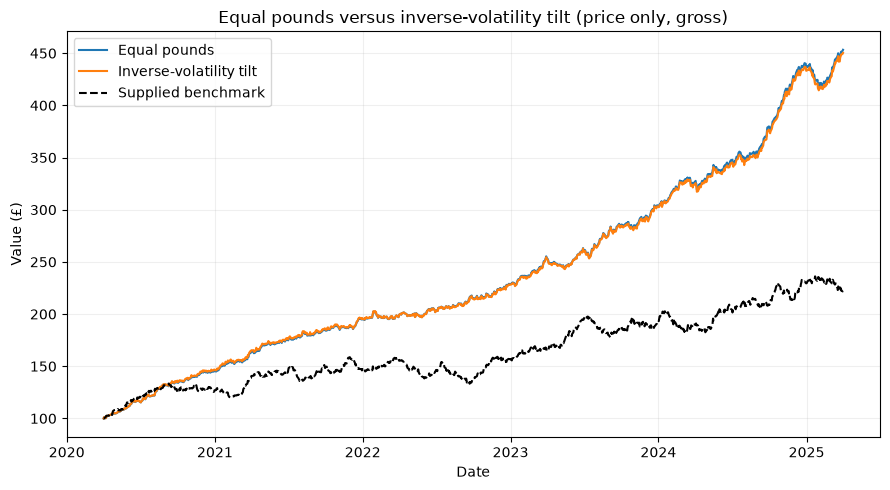

Saved weighting comparison tables and chart under results/.


In [14]:
from src.research.backtesting import run_volatility_tilt_study

volatility_tilt_study = run_volatility_tilt_study(annual, prices, holding_count=5, budget_gbp=100_000)
weighting_summary = volatility_tilt_study["summary"].copy()
for column in ["cagr", "annualised_volatility", "max_drawdown", "benchmark_relative_return"]:
    weighting_summary[column] *= 100
weighting_summary = weighting_summary.rename(columns={
    "cagr": "CAGR (%)", "annualised_volatility": "Volatility (% annual)",
    "max_drawdown": "Maximum drawdown (%)",
    "benchmark_relative_return": "Cumulative relative return vs benchmark (%)",
})
print("Same top-five score selections; equal-pound and inverse-volatility stock weights")
display(weighting_summary.round(3))

positions = volatility_tilt_study["current_positions"].copy()
positions["Equal weight (%)"] = positions.equal_weight * 100
positions["Inverse-volatility weight (%)"] = positions.inverse_volatility_weight * 100
position_columns = ["ticker", "company", "sector", "annualised_volatility", "share_price_gbp",
    "Equal weight (%)", "equal_budget_gbp", "equal_whole_shares", "equal_residual_cash_gbp",
    "Inverse-volatility weight (%)", "tilted_budget_gbp", "tilted_whole_shares", "tilted_residual_cash_gbp"]
print("31 December 2025 positions and whole-share examples; prices and budget amounts are GBP")
display(positions[position_columns].rename(columns={
    "annualised_volatility": "Trailing 12-month volatility (fraction)",
    "share_price_gbp": "Closing price (£)",
    "equal_budget_gbp": "Equal budget (£)", "equal_whole_shares": "Equal whole shares",
    "equal_residual_cash_gbp": "Equal residual cash (£)",
    "tilted_budget_gbp": "Tilted budget (£)", "tilted_whole_shares": "Tilted whole shares",
    "tilted_residual_cash_gbp": "Tilted residual cash (£)",
}).round(2))

results_directory = project_root / "results"
volatility_tilt_study["summary"].to_csv(results_directory / "volatility_tilt_backtest_summary.csv", index=False)
positions[position_columns].to_csv(results_directory / "volatility_tilt_2025_positions.csv", index=False)
fig, ax = plt.subplots(figsize=(9, 5))
for weighting, group in volatility_tilt_study["nav"].query("cost_bps == 0").groupby("weighting"):
    ax.plot(group.Date, group.nav * 100, label=weighting)
benchmark = volatility_tilt_study["nav"].query("cost_bps == 0").drop_duplicates("Date")
ax.plot(benchmark.Date, benchmark.benchmark_nav * 100, color="black", linestyle="--", label="Supplied benchmark")
ax.set(title="Equal pounds versus inverse-volatility tilt (price only, gross)", xlabel="Date", ylabel="Value (£)")
ax.grid(alpha=.2)
ax.legend()
fig.tight_layout()
volatility_plot = results_directory / "volatility_tilt_backtest.png"
fig.savefig(volatility_plot, dpi=150, bbox_inches="tight")
plt.show()
print("Saved weighting comparison tables and chart under results/.")

## 12. Dividends, scenarios and further investigation

- **Dividends remain a sustainability check.** Payment dates and historical dividend cash flows are unavailable. A price-only test can understate dividend-paying companies' total returns.
- **Economic exposures remain scenario inputs.** End-2025 refinancing, optional-demand, infrastructure, essential-technology and routine-care estimates cannot be assumed to apply in 2020. Numeric energy exposure and bank income sensitivities are unavailable.
- **The universe is small and fixed.** The supplied 20 companies are accepted as given; the experiment cannot establish their representativeness or eliminate survivorship effects.
- **The common sample contains five annual periods.** Higher returns may reflect sector concentration or one favourable year. Inspect the financial trends and factsheets before drawing an investment conclusion.
- **Costs are illustrative and dividends are excluded.** These results do not measure after-tax total shareholder returns.

Further evidence would require more independent companies, more complete annual periods, dividend histories and historical company exposures.

In [15]:
print("Saved outputs:")
for label, value in artifacts.items():
    if label != "plots":
        print(label, ":", value)
print("Saved plot files:")
for title, image_path in artifacts["plots"].items():
    print(title, ":", image_path)

Saved outputs:
summary : /Users/jsisthejbest/Desktop/jupiterjupyter/quant_project/results/factor_backtest_summary.csv
nav : /Users/jsisthejbest/Desktop/jupiterjupyter/quant_project/results/factor_backtest_nav.csv
returns : /Users/jsisthejbest/Desktop/jupiterjupyter/quant_project/results/factor_backtest_returns.csv
selections : /Users/jsisthejbest/Desktop/jupiterjupyter/quant_project/results/factor_backtest_selections.csv
forward_returns : /Users/jsisthejbest/Desktop/jupiterjupyter/quant_project/results/factor_backtest_forward_returns.csv
period_returns : /Users/jsisthejbest/Desktop/jupiterjupyter/quant_project/results/factor_backtest_period_returns.csv
weights : /Users/jsisthejbest/Desktop/jupiterjupyter/quant_project/results/factor_backtest_weights.csv
overlap : /Users/jsisthejbest/Desktop/jupiterjupyter/quant_project/results/factor_backtest_overlap.csv
blend_summary : /Users/jsisthejbest/Desktop/jupiterjupyter/quant_project/results/factor_backtest_blend_summary.csv
blend_nav : /Users

> **Assignment scope:** The proposed portfolio follows buy-and-hold. Annual-reselection backtests elsewhere in this notebook are methodological references only; the three-year comparison below is the relevant holding-period test.


## ⭐ 13. Three-year holding periods
Select five stocks using information known at each start, then compare holding them for three years with annual reselection. Initial stock weights are 20%; factor weights are one-sixth. Windows overlap and are not independent experiments. Returns exclude dividends; costs are charged on purchases and sales. Benchmark returns are the supplied price index without trading costs.


/var/folders/9b/zgn73v8j45s_hg_rw09skl7m0000gn/T/ipykernel_44434/3610346339.py:5: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(three_year['summary'].round(4))


,window_start,method,cost_bps,start_date,end_date,cumulative_return,ending_value_gbp,benchmark_return,cagr,annualised_volatility,sharpe,max_drawdown,turnover_annualised,benchmark_relative_return
0,2020,Buy and hold,0,2020-04-01,2023-04-03,1.3250,232496.9291,0.6453,0.3243,0.0794,3.1931,-0.0372,0.0000,0.4131
1,2020,Buy and hold,25,2020-04-01,2023-04-03,1.3134,231337.3434,0.6453,0.3221,0.0795,3.1691,-0.0372,0.0000,0.4061
2,2020,Annual reselection,0,2020-04-01,2023-04-03,1.5255,252552.5181,0.6453,0.3613,0.0785,3.5803,-0.0358,0.1045,0.5350
3,2020,Annual reselection,25,2020-04-01,2023-04-03,1.5090,250898.6761,0.6453,0.3584,0.0785,3.5493,-0.0358,0.1045,0.5250
4,2021,Buy and hold,0,2021-04-01,2024-04-02,0.9421,194206.3122,0.3515,0.2473,0.0778,2.4961,-0.0403,0.0000,0.4369
5,2021,Buy and hold,25,2021-04-01,2024-04-02,0.9324,193237.7022,0.3515,0.2452,0.0778,2.4751,-0.0403,0.0000,0.4298
6,2021,Annual reselection,0,2021-04-01,2024-04-02,0.9982,199816.7884,0.3515,0.2592,0.0756,2.6919,-0.0456,0.1092,0.4785
7,2021,Annual reselection,25,2021-04-01,2024-04-02,0.9849,198494.1944,0.3515,0.2564,0.0755,2.6648,-0.0460,0.1092,0.4687
8,2022,Buy and hold,0,2022-04-01,2025-04-01,1.4405,244053.5985,0.4348,0.3463,0.0772,3.4948,-0.0636,0.0000,0.7010
9,2022,Buy and hold,25,2022-04-01,2025-04-01,1.4284,242836.3736,0.4348,0.3440,0.0772,3.4741,-0.0636,0.0000,0.6925


,window_start,method,execution_date,ticker,sector,score
3,2020,Buy and hold,2020-04-01,ORP,Healthcare,0.821554
5,2020,Buy and hold,2020-04-01,MGS,Technology,0.770254
11,2020,Buy and hold,2020-04-01,FFF,Consumer,0.702823
13,2020,Buy and hold,2020-04-01,CSE,Industrials,0.692576
18,2020,Buy and hold,2020-04-01,BFC,Technology,0.765686
23,2020,Annual reselection,2020-04-01,ORP,Healthcare,0.821554
25,2020,Annual reselection,2020-04-01,MGS,Technology,0.770254
31,2020,Annual reselection,2020-04-01,FFF,Consumer,0.702823
33,2020,Annual reselection,2020-04-01,CSE,Industrials,0.692576
38,2020,Annual reselection,2020-04-01,BFC,Technology,0.765686


,window_start,method,signal_date,ticker,reason
0,2020,Buy and hold,2020-03-31,VTF,Eligible on all six factors
2,2020,Buy and hold,2020-03-31,QCK,At least one factor score undefined
8,2020,Buy and hold,2020-03-31,VGB,Eligible on all six factors
12,2020,Buy and hold,2020-03-31,FAI,Eligible on all six factors
14,2020,Buy and hold,2020-03-31,CRM,Eligible on all six factors
...,...,...,...,...,...
228,2022,Annual reselection,2024-03-31,VGB,Eligible on all six factors
232,2022,Annual reselection,2024-03-31,FAI,Eligible on all six factors
234,2022,Annual reselection,2024-03-31,CRM,Eligible on all six factors
235,2022,Annual reselection,2024-03-31,CDB,Eligible on all six factors


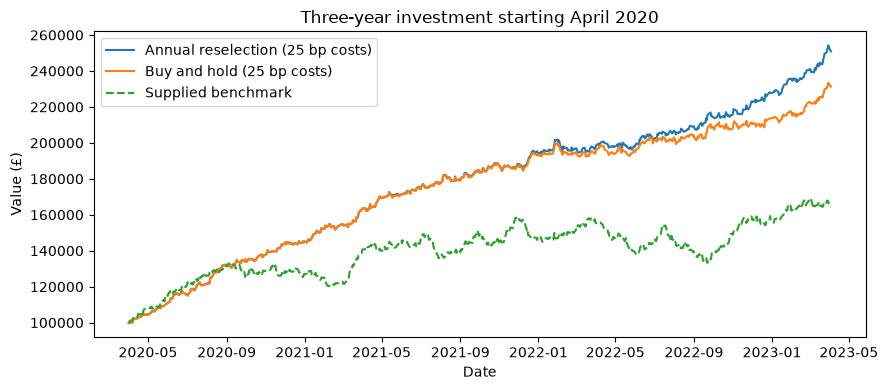

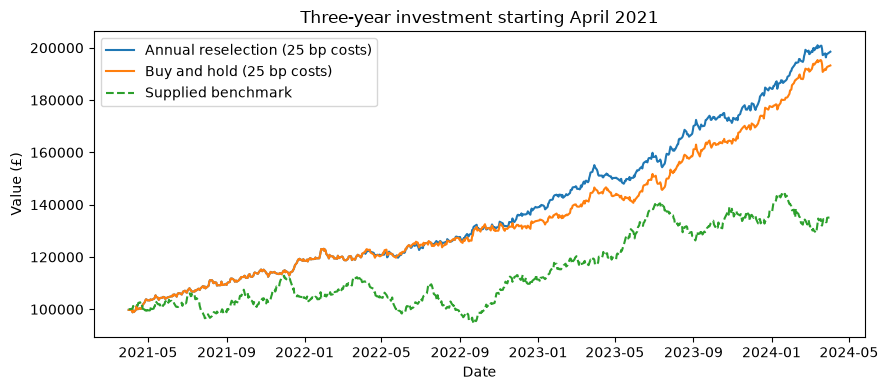

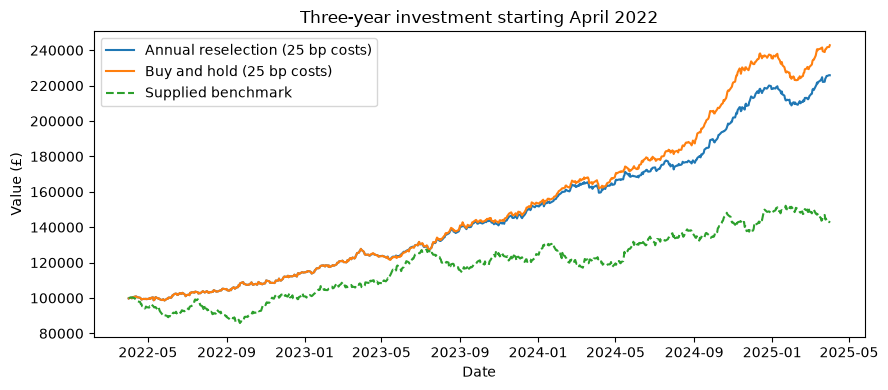

In [16]:
from src.research.backtesting import run_three_year_study
three_year = run_three_year_study(annual, prices)
for name, frame in three_year.items():
    frame.to_csv(project_root / 'results' / f'three_year_{name}.csv', index=False)
display(three_year['summary'].round(4))
display(three_year['selections'].loc[lambda x: x.selected, ['window_start', 'method', 'execution_date', 'ticker', 'sector', 'score']])
display(three_year['selections'].loc[lambda x: ~x.eligible, ['window_start', 'method', 'signal_date', 'ticker', 'reason']])
for year in (2020, 2021, 2022):
    fig, ax = plt.subplots(figsize=(9, 4))
    paths = three_year['nav'].query('window_start == @year and cost_bps == 25')
    for method, frame in paths.groupby('method'):
        ax.plot(frame.Date, frame.nav * 100000, label=method + ' (25 bp costs)')
    benchmark = paths.drop_duplicates('Date')
    ax.plot(benchmark.Date, benchmark.benchmark_nav * 100000, label='Supplied benchmark', linestyle='--')
    ax.set(title=f'Three-year investment starting April {year}', ylabel='Value (£)', xlabel='Date')
    ax.legend(); fig.tight_layout()
    fig.savefig(project_root / 'results' / f'three_year_{year}.png', dpi=150)
    plt.show()




### ⭐ Three-year holding-period evidence

Three overlapping windows compare holding the original five stocks with annual reselection. Both begin at 20% per stock and use equal six-factor scores known at each decision date. Results below include 25 basis points per purchase/sale and exclude dividends.

| Start | Buy-and-hold CAGR | Annual reselection CAGR |
|---|---:|---:|
| April 2020 | 32.21% | 35.84% |
| April 2021 | 24.52% | 25.64% |
| April 2022 | 34.40% | 31.20% |

Annual reselection led in two windows; buy-and-hold led in one. These shared calendar years are not independent experiments and do not establish a superior future policy. The historical holdings are selected at each historical start, rather than retrospectively imposing our proposed 2025 holdings. Review frequency remains a policy choice requiring further evidence.
